In [27]:
import numpy as np
import csv
import pandas as pd
from scipy.signal import find_peaks
#import seaborn as sns
import matplotlib.pyplot as plt
import scipy as sp
import os
from pathlib import Path
import joblib
import glob

In [28]:
SAVEDIR = Path(os.path.expanduser("~/ECM_mod_output/UMAP/"))
if not os.path.exists(SAVEDIR):
    os.mkdir(SAVEDIR)
    
LOADDIR = Path(os.path.expanduser("C:/Program Files/MATLAB/R2022a/ECM_UMAP_output"))

In [26]:
#Important params to set the window size and step time distance
init_dt = 0.01                #initial dt from the raw model output
dt = 0.05                      #dt for umap window
window = 2                    #window size in hours
time_step = 1                 #time step between windows

#Load umap reducer object
#reducer = joblib.load(str(SAVEDIR) + '\\reducer_09_04_0.01_0.05_2_0.1.sav')

In [29]:
f = "C:\\Program Files\\MATLAB/R2022a\\ECM_UMAP_output\\cells_60_20_100.csv"
prot_tmp = pd.read_csv(f, sep=",")

In [ ]:
prot_tmp

In [30]:
def calc_cell_UMAP(prot_tmp):
    umap_df = pd.DataFrame(columns = ['id', 'Event', 'UMAP1', 'UMAP2'])
    for val in prot_tmp.id.unique():    
        tmp_df = prot_tmp.loc[prot_tmp['id'] == val]
        time_tmp = tmp_df['time']
        time_tmp2 = time_tmp.iloc[::int(dt//init_dt)].reset_index().drop(columns=['index'])
        if time_tmp2.iloc[-1,0] - time_tmp2.iloc[0,0] > window:

            #create window and total protein arrays
            win_len = int(window/dt)
            range_ind = np.arange(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt))

            prot_tmp2 = tmp_df.iloc[::int(dt//init_dt),4:22].reset_index().drop(columns=['index'])

            prot_re_tmp = np.empty((len(range_ind),win_len*18))
            time_re_tmp = np.empty((len(range_ind),win_len))
            time_at_tmp = np.empty((len(range_ind),1))

            ii=0
            for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
                tmp = prot_tmp2.iloc[n-int(win_len/2):n+int(win_len/2)]
                tmp_t = time_tmp2['time'].iloc[n-int(win_len/2):n+int(win_len/2)]
                tmp=tmp.to_numpy()
                tmp=np.reshape(np.transpose(tmp),win_len*18)
                tmp_at = time_tmp2['time'].iloc[n]

                prot_re_tmp[ii,:] = np.array([tmp])
                time_re_tmp[ii,:] = np.array([tmp_t])
                time_at_tmp[ii,:] = np.array([[tmp_at]])
                ii+=1
            embedding_all_prot = reducer.transform(prot_re_tmp)
            umap_df_tmp = pd.DataFrame(columns = ['id', 'Event', 'UMAP1', 'UMAP2'])
            umap_df_tmp['UMAP1'] = embedding_all_prot[:,0]
            umap_df_tmp['UMAP2'] = embedding_all_prot[:,1]
            umap_df_tmp['id'] = val
            if tmp_df.iloc[0,2] == 0 and tmp_df.iloc[0,1] == 0:
                umap_df_tmp['Event'] = 'Division'
            elif tmp_df.iloc[0,2] == 1:
                umap_df_tmp['Event'] = 'Death'
            else:
                umap_df_tmp['Event'] = 'EoE'
            umap_df = pd.concat([umap_df,umap_df_tmp],ignore_index=True)
            
    return umap_df

In [ ]:
umap_df_1 = calc_cell_UMAP(prot_tmp)

In [ ]:
for val in umap_df_1.id.unique(): 
    tmp_df = umap_df_1.loc[umap_df_1['id'] == val]
    if tmp_df.iloc[0,1] == 'Division':
        plt.plot(tmp_df['UMAP1'], tmp_df['UMAP2'], c='green', lw=0.5)
    elif tmp_df.iloc[0,1] == 'EoE':
        plt.plot(tmp_df['UMAP1'], tmp_df['UMAP2'], c='blue', lw=0.5)
    else:
        plt.plot(tmp_df['UMAP1'], tmp_df['UMAP2'], c='red', lw=0.5)
        

In [ ]:
umap_df_2 = calc_cell_UMAP(prot_tmp)
umap_df_2

In [ ]:
for val in umap_df_2.id.unique(): 
    tmp_df = umap_df_2.loc[umap_df_2['id'] == val]
    if tmp_df.iloc[0,1] == 'Division':
        plt.plot(tmp_df['UMAP1'], tmp_df['UMAP2'], c='green', lw=0.5)
    elif tmp_df.iloc[0,1] == 'EoE':
        if tmp_df['time'][-1] - tmp_df['time'][0] > 50:
            plt.plot(tmp_df['UMAP1'], tmp_df['UMAP2'], c='blue', lw=0.5)
    else:
        plt.plot(tmp_df['UMAP1'], tmp_df['UMAP2'], c='red', lw=0.5)

In [ ]:
umap_df_3 = calc_cell_UMAP(prot_tmp)

In [ ]:
for val in umap_df_3.id.unique(): 
    tmp_df = umap_df_3.loc[umap_df_3['id'] == val]
    if tmp_df.iloc[0,1] == 'Division':
        plt.plot(tmp_df['UMAP1'], tmp_df['UMAP2'], c='green', lw=0.5)
    elif tmp_df.iloc[0,1] == 'EoE':
        plt.plot(tmp_df['UMAP1'], tmp_df['UMAP2'], c='blue', lw=0.5)
    else:
        plt.plot(tmp_df['UMAP1'], tmp_df['UMAP2'], c='red', lw=0.5)

In [ ]:
for val in umap_df_1.id.unique(): 
    tmp_df = umap_df_1.loc[umap_df_1['id'] == val]
    if tmp_df.iloc[0,1] == 'Division':
        plt.plot(tmp_df['UMAP1'], tmp_df['UMAP2'], c='green')
    elif tmp_df.iloc[0,1] == 'EoE':
        plt.plot(tmp_df['UMAP1'], tmp_df['UMAP2'], c='blue')
    else:
        plt.plot(tmp_df['UMAP1'], tmp_df['UMAP2'], c='red')

In [31]:
file_location = os.path.join('C:\\Program Files\\MATLAB\\R2022a\\ECM_UMAP_output\\cell_fates\\', '*.csv')
filenames = glob.glob(file_location)

In [32]:
filenames

['C:\\Program Files\\MATLAB\\R2022a\\ECM_UMAP_output\\cell_fates\\cells_deaths_30_20_40.csv',
 'C:\\Program Files\\MATLAB\\R2022a\\ECM_UMAP_output\\cell_fates\\cells_divs_100_100_100.csv',
 'C:\\Program Files\\MATLAB\\R2022a\\ECM_UMAP_output\\cell_fates\\cells_divs_100_100_60.csv',
 'C:\\Program Files\\MATLAB\\R2022a\\ECM_UMAP_output\\cell_fates\\cells_divs_30_20_40.csv',
 'C:\\Program Files\\MATLAB\\R2022a\\ECM_UMAP_output\\cell_fates\\cells_divs_60_100_40.csv',
 'C:\\Program Files\\MATLAB\\R2022a\\ECM_UMAP_output\\cell_fates\\cells_divs_60_20_100.csv',
 'C:\\Program Files\\MATLAB\\R2022a\\ECM_UMAP_output\\cell_fates\\cells_divs_60_20_60.csv',
 'C:\\Program Files\\MATLAB\\R2022a\\ECM_UMAP_output\\cell_fates\\cells_eoe_30_20_40.csv']

In [33]:
v_names = ['id', 'eoe', 'death', 'time', 'Skp2', 'p21', 'p21p', 'Cdh1', 'Myc', 'CycD', 'CycDp21',
    'Rb', 'pRb', 'E2F', 'RbE2F', 'CycE', 'CycEp21', 'CycA', 'CycAp21', 'CycB', 'CycBp21', 'Cdc20',
    'BAX', 'BAXmBCL2', 'BH3', 'BH3BCL2', 'BAXm', 'BCL2']
all_fates = pd.DataFrame(columns = v_names)

In [34]:
all_fates

,id,eoe,death,time,Skp2,p21,p21p,Cdh1,Myc,CycD,...,CycAp21,CycB,CycBp21,Cdc20,BAX,BAXmBCL2,BH3,BH3BCL2,BAXm,BCL2


In [35]:
all_fates = pd.DataFrame(columns = v_names)
id_num = 0
for f in filenames:
    df_tmp = pd.read_csv(f, sep=",")
    df_tmp['id'] = [row + id_num for row in df_tmp['id']]
    all_fates = pd.concat([all_fates, df_tmp])
    id_num += 200
        
    

In [37]:
#Important params to set the window size and step time distance
init_dt = 0.01                #initial dt from the raw model output
dt = 0.02                      #dt for umap window
window = 1                    #window size in hours
time_step = 0.2                 #time step between windows

#umap params
neighbs = 500
min_d = 0.05

#reducer save name
r_name = f'\\reducer_09_25_fates_{init_dt}_{dt}_{window}_{time_step}.sav'

In [38]:
def calc_cell_UMAP_red(prot_tmp):
    win_len = int(window/dt)
    all_prot_tmp = np.empty((0,win_len*18))     #careful, this could end up being massive 
    all_time_tmp = np.empty((0,win_len))
    all_time_at_tmp = np.empty((0,1))
    cell_ind = pd.DataFrame(columns=['id'])
    counts = 0
    
    for val in prot_tmp.id.unique():    
        tmp_df = prot_tmp.loc[prot_tmp['id'] == val]
        time_tmp = tmp_df['time']
        time_tmp2 = time_tmp.iloc[::int(dt//init_dt)].reset_index().drop(columns=['index'])
        range_ind = np.arange(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt))
        if time_tmp2.iloc[-1,0] - time_tmp2.iloc[0,0] > window:

            #create window and total protein arrays
            #range_ind = np.arange(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt))

            prot_tmp2 = tmp_df.iloc[::int(dt//init_dt),4:22].reset_index().drop(columns=['index'])

            prot_re_tmp = np.empty((len(range_ind),win_len*18))
            time_re_tmp = np.empty((len(range_ind),win_len))
            time_at_tmp = np.empty((len(range_ind),1))

            ii=0
            for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
                tmp = prot_tmp2.iloc[n-int(win_len/2):n+int(win_len/2)]
                tmp_t = time_tmp2['time'].iloc[n-int(win_len/2):n+int(win_len/2)]
                tmp=tmp.to_numpy()
                tmp=np.reshape(np.transpose(tmp),win_len*18)
                tmp_at = time_tmp2['time'].iloc[n]

                prot_re_tmp[ii,:] = np.array([tmp])
                time_re_tmp[ii,:] = np.array([tmp_t])
                time_at_tmp[ii,:] = np.array([[tmp_at]])
                ii+=1
            
            tmp_ind = pd.DataFrame(data=np.ones(prot_re_tmp.shape[0])*val, columns=['id'])
            cell_ind = pd.concat([cell_ind, tmp_ind], ignore_index=True)
            all_prot_tmp = np.append(all_prot_tmp, prot_re_tmp, axis=0)
            all_time_tmp = np.append(all_time_tmp, time_re_tmp, axis=0)
            all_time_at_tmp = np.append(all_time_at_tmp, time_at_tmp, axis=0)

            
    return all_prot_tmp, all_time_tmp, all_time_at_tmp, cell_ind

In [39]:
all_prot_tmp, all_time_tmp, all_time_at_tmp, cell_ind= calc_cell_UMAP_red(all_fates)

In [40]:
test = cell_ind[(cell_ind.id > 200) & (cell_ind.id < 401)]
tmp = all_prot_tmp[test.index]

In [41]:
len(all_prot_tmp)

225187

In [42]:
import umap

In [ ]:
# reducer = umap.UMAP(
#         n_neighbors=neighbs,
#         min_dist=min_d,
#         n_components=2,
#         metric='euclidean',
#         random_state=42,
#         low_memory=True        
#         ).fit(all_prot_tmp)

# embedding_all_prot = reducer.transform(all_prot_tmp)

In [ ]:
joblib.dump(reducer, str(SAVEDIR) + r_name)

In [43]:
reducer = joblib.load(str(SAVEDIR) + f'\\reducer_09_25_{init_dt}_{dt}_{window}_{time_step}.sav')

In [ ]:
embedding_all_prot = reducer.transform(all_prot_tmp)

In [17]:
imt_max = 30
imt_min = 22
from matplotlib import cm, colors


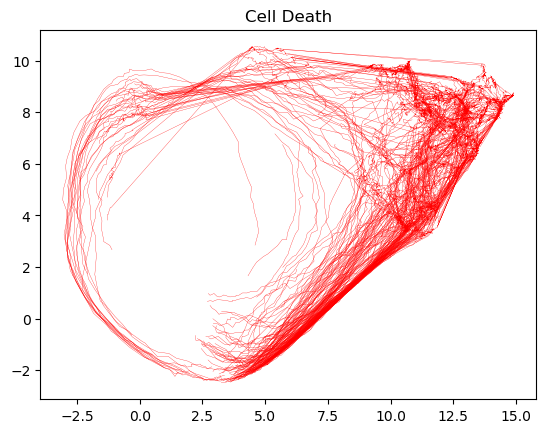

In [24]:
for val in range(1,200):
    tmp_id = cell_ind.index[cell_ind['id'] == val].tolist()
    plt.plot(embedding_all_prot[tmp_id,0], embedding_all_prot[tmp_id,1], c='red', lw=0.2)
    plt.title('Cell Death')

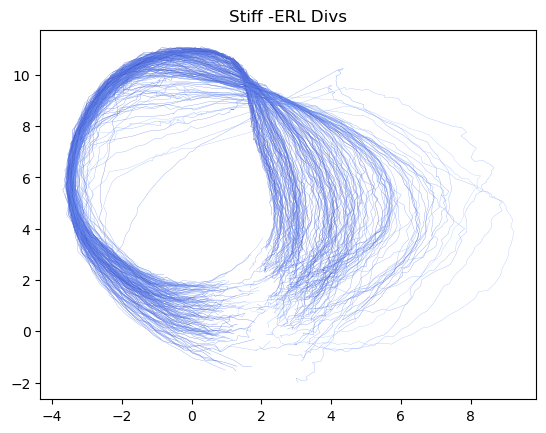

In [79]:
win_time = []
for val in range(201,400):
    tmp_id = cell_ind.index[cell_ind['id'] == val].tolist()
    win_time.append(all_time_at_tmp[tmp_id[-1]] - all_time_at_tmp[tmp_id[0]])
    
cmap = cm.coolwarm
cnorm = colors.Normalize(vmin=15, vmax=45)
    

ii=0
for val in range(201,400):
    tmp_id = cell_ind.index[cell_ind['id'] == val].tolist()
    if all_time_at_tmp[tmp_id[-1]] - all_time_at_tmp[tmp_id[0]] < imt_min:
        plt.plot(embedding_all_prot[tmp_id,0], embedding_all_prot[tmp_id,1], color=cmap(cnorm(win_time[ii])), lw=0.2)
    elif all_time_at_tmp[tmp_id[-1]] - all_time_at_tmp[tmp_id[0]] > imt_max:
        plt.plot(embedding_all_prot[tmp_id,0], embedding_all_prot[tmp_id,1], color=cmap(cnorm(win_time[ii])), lw=0.2)
    else:
        plt.plot(embedding_all_prot[tmp_id,0], embedding_all_prot[tmp_id,1], color=cmap(cnorm(win_time[ii])), lw=0.2)
    ii+=1
    plt.title('Stiff -ERL Divs')

In [31]:
win_time

[array([0.17333333]),
 array([0.15]),
 array([0.14833333]),
 array([0.13833333]),
 array([0.13333333]),
 array([0.165]),
 array([0.13166667]),
 array([0.15166667]),
 array([0.14166667]),
 array([0.13666667]),
 array([0.16833333]),
 array([0.14]),
 array([0.16666667]),
 array([0.13666667]),
 array([0.155]),
 array([0.14166667]),
 array([0.135]),
 array([0.145]),
 array([0.13833333]),
 array([0.215]),
 array([0.10666667]),
 array([0.165]),
 array([0.12333333]),
 array([0.16333333]),
 array([0.13]),
 array([0.15]),
 array([0.17]),
 array([0.15833333]),
 array([0.15833333]),
 array([0.15666667]),
 array([0.14666667]),
 array([0.17]),
 array([0.16]),
 array([0.15833333]),
 array([0.13]),
 array([0.15166667]),
 array([0.16]),
 array([0.16166667]),
 array([0.12333333]),
 array([0.14166667]),
 array([0.13666667]),
 array([0.14333333]),
 array([0.13166667]),
 array([0.15]),
 array([0.16166667]),
 array([0.15666667]),
 array([0.17166667]),
 array([0.13666667]),
 array([0.15]),
 array([0.17333333

array([ True])

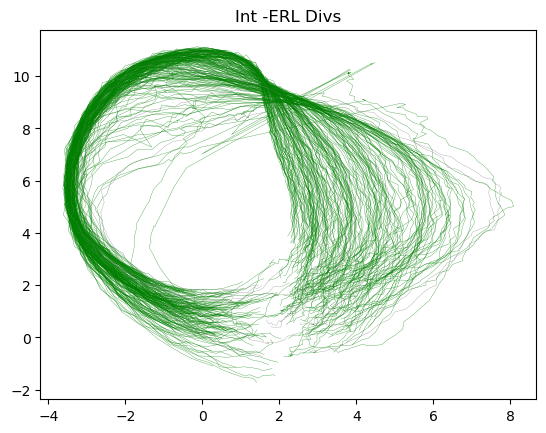

In [85]:
for val in range(401,600):
    tmp_id = cell_ind.index[cell_ind['id'] == val].tolist()
    if all_time_at_tmp[tmp_id[-1]] - all_time_at_tmp[tmp_id[0]] < imt_min:
        plt.plot(embedding_all_prot[tmp_id,0], embedding_all_prot[tmp_id,1], c='green', lw=0.2)
    elif all_time_at_tmp[tmp_id[-1]] - all_time_at_tmp[tmp_id[0]] > imt_max:
        plt.plot(embedding_all_prot[tmp_id,0], embedding_all_prot[tmp_id,1], c='red', lw=0.2)
    else:
        plt.plot(embedding_all_prot[tmp_id,0], embedding_all_prot[tmp_id,1], c='grey', lw=0.2)
    plt.title('Int -ERL Divs')

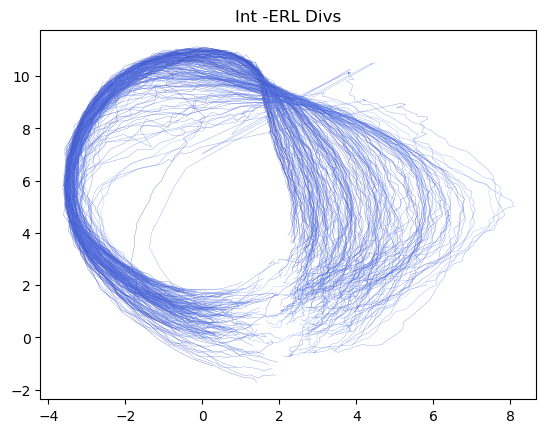

In [67]:
win_time = []
for val in range(401,600):
    tmp_id = cell_ind.index[cell_ind['id'] == val].tolist()
    win_time.append(all_time_at_tmp[tmp_id[-1]] - all_time_at_tmp[tmp_id[0]])
    
cmap = cm.coolwarm
cnorm = colors.Normalize(vmin=15, vmax=60)
    

ii=0
for val in range(401,600):
    tmp_id = cell_ind.index[cell_ind['id'] == val].tolist()
    plt.plot(embedding_all_prot[tmp_id,0], embedding_all_prot[tmp_id,1], color=cmap(cnorm(win_time[ii])), lw=0.2)
    ii+=1
    plt.title('Int -ERL Divs')


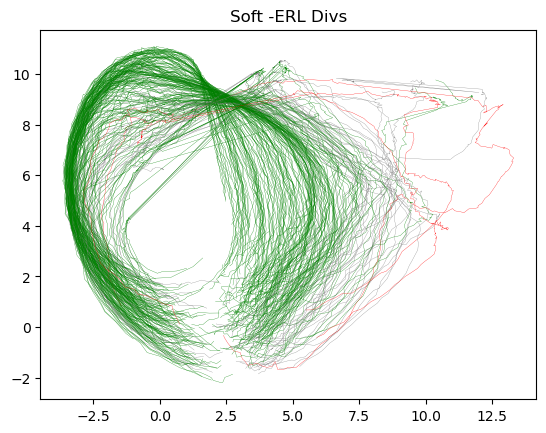

In [88]:
for val in range(801,1000):
    tmp_id = cell_ind.index[cell_ind['id'] == val].tolist()
    if all_time_at_tmp[tmp_id[-1]] - all_time_at_tmp[tmp_id[0]] < imt_min:
        plt.plot(embedding_all_prot[tmp_id,0], embedding_all_prot[tmp_id,1], c='green', lw=0.2)
    elif all_time_at_tmp[tmp_id[-1]] - all_time_at_tmp[tmp_id[0]] > imt_max:
        plt.plot(embedding_all_prot[tmp_id,0], embedding_all_prot[tmp_id,1], c='red', lw=0.2)
    else:
        plt.plot(embedding_all_prot[tmp_id,0], embedding_all_prot[tmp_id,1], c='grey', lw=0.2)
    plt.title('Soft -ERL Divs')

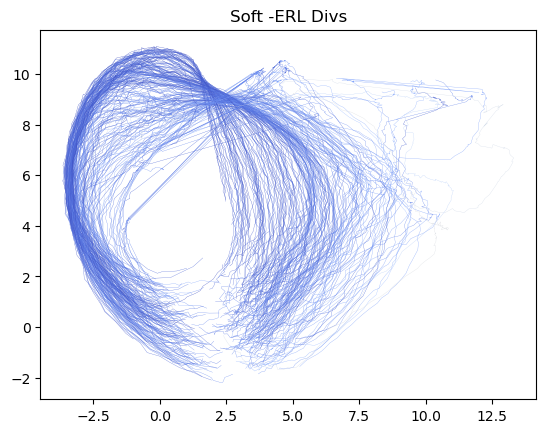

In [69]:
win_time = []
for val in range(801,1000):
    tmp_id = cell_ind.index[cell_ind['id'] == val].tolist()
    win_time.append(all_time_at_tmp[tmp_id[-1]] - all_time_at_tmp[tmp_id[0]])
    
cmap = cm.coolwarm
cnorm = colors.Normalize(vmin=15, vmax=60)
    

ii=0
for val in range(801,1000):
    tmp_id = cell_ind.index[cell_ind['id'] == val].tolist()
    plt.plot(embedding_all_prot[tmp_id,0], embedding_all_prot[tmp_id,1], color=cmap(cnorm(win_time[ii])), lw=0.2)
    ii+=1
    plt.title('Soft -ERL Divs')

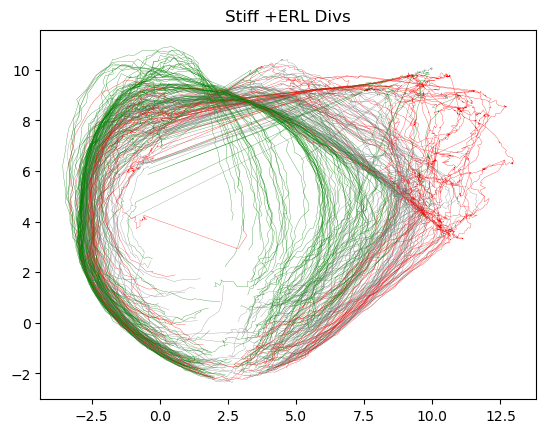

In [89]:
for val in range(1001,1200):
    tmp_id = cell_ind.index[cell_ind['id'] == val].tolist()
    if all_time_at_tmp[tmp_id[-1]] - all_time_at_tmp[tmp_id[0]] < 22:
        plt.plot(embedding_all_prot[tmp_id,0], embedding_all_prot[tmp_id,1], c='green', lw=0.2)
    elif all_time_at_tmp[tmp_id[-1]] - all_time_at_tmp[tmp_id[0]] > 30:
        plt.plot(embedding_all_prot[tmp_id,0], embedding_all_prot[tmp_id,1], c='red', lw=0.2)
    else:
        plt.plot(embedding_all_prot[tmp_id,0], embedding_all_prot[tmp_id,1], c='grey', lw=0.2)
    plt.title('Stiff +ERL Divs')

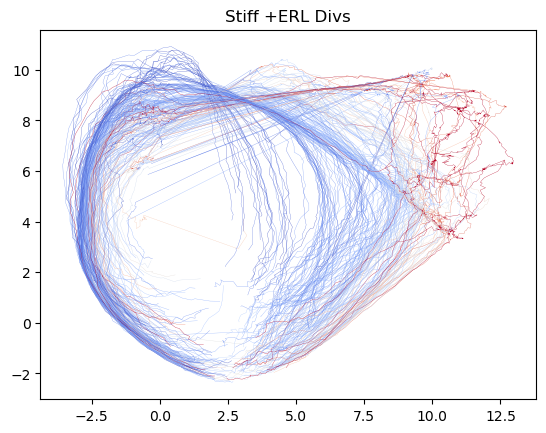

In [77]:
win_time = []
for val in range(1001,1200):
    tmp_id = cell_ind.index[cell_ind['id'] == val].tolist()
    win_time.append(all_time_at_tmp[tmp_id[-1]] - all_time_at_tmp[tmp_id[0]])
    
cmap = cm.coolwarm
cnorm = colors.Normalize(vmin=15, vmax=45)
    

ii=0
for val in range(1001,1200):
    tmp_id = cell_ind.index[cell_ind['id'] == val].tolist()
    plt.plot(embedding_all_prot[tmp_id,0], embedding_all_prot[tmp_id,1], color=cmap(cnorm(win_time[ii])), lw=0.2)
    ii+=1
    plt.title('Stiff +ERL Divs')
    


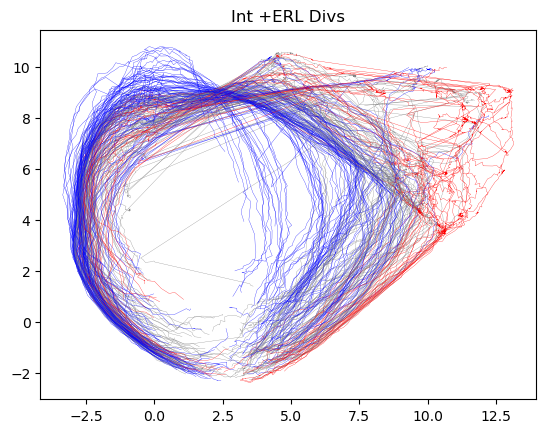

In [80]:
for val in range(1201,1400):
    tmp_id = cell_ind.index[cell_ind['id'] == val].tolist()
    if all_time_at_tmp[tmp_id[-1]] - all_time_at_tmp[tmp_id[0]] < 22:
        plt.plot(embedding_all_prot[tmp_id,0], embedding_all_prot[tmp_id,1], c='blue', lw=0.2)
        
    elif all_time_at_tmp[tmp_id[-1]] - all_time_at_tmp[tmp_id[0]] > 30:
        plt.plot(embedding_all_prot[tmp_id,0], embedding_all_prot[tmp_id,1], c='red', lw=0.2)
    else:
        plt.plot(embedding_all_prot[tmp_id,0], embedding_all_prot[tmp_id,1], c='grey', lw=0.2)
        
    plt.title('Int +ERL Divs')

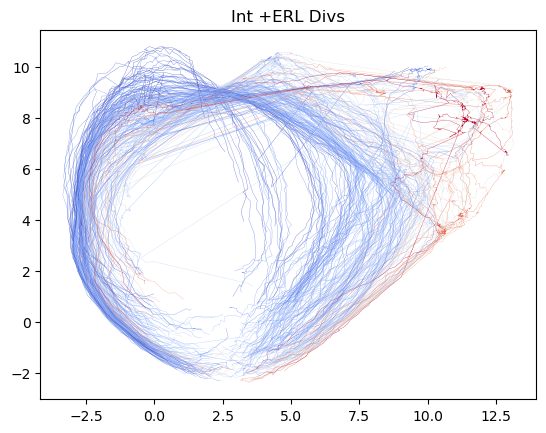

In [75]:
win_time = []
for val in range(1201,1400):
    tmp_id = cell_ind.index[cell_ind['id'] == val].tolist()
    win_time.append(all_time_at_tmp[tmp_id[-1]] - all_time_at_tmp[tmp_id[0]])
    
cmap = cm.coolwarm
cnorm = colors.Normalize(vmin=15, vmax=45)
    

ii=0
for val in range(1201,1400):
    tmp_id = cell_ind.index[cell_ind['id'] == val].tolist()
    plt.plot(embedding_all_prot[tmp_id,0], embedding_all_prot[tmp_id,1], color=cmap(cnorm(win_time[ii])), lw=0.2)
    ii+=1
    plt.title('Int +ERL Divs')

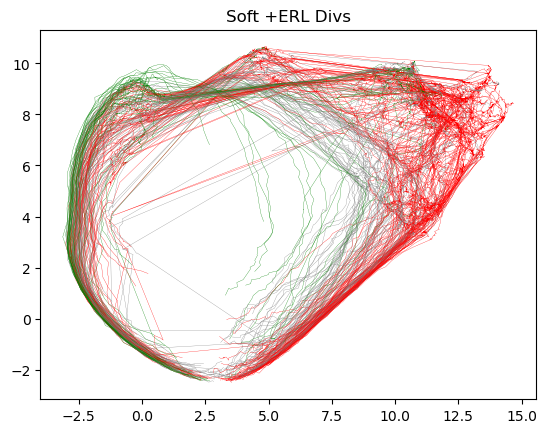

In [51]:
for val in range(601,800):
    tmp_id = cell_ind.index[cell_ind['id'] == val].tolist()
    if all_time_at_tmp[tmp_id[-1]] - all_time_at_tmp[tmp_id[0]] < 22:
        plt.plot(embedding_all_prot[tmp_id,0], embedding_all_prot[tmp_id,1], c='green', lw=0.2)
    elif all_time_at_tmp[tmp_id[-1]] - all_time_at_tmp[tmp_id[0]] > 30:
        plt.plot(embedding_all_prot[tmp_id,0], embedding_all_prot[tmp_id,1], c='red', lw=0.2)
    else:
        plt.plot(embedding_all_prot[tmp_id,0], embedding_all_prot[tmp_id,1], c='grey', lw=0.2)
    plt.title('Soft +ERL Divs')

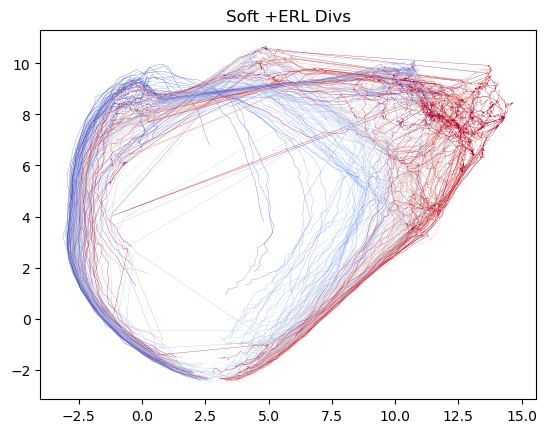

In [76]:
win_time = []
for val in range(601,800):
    tmp_id = cell_ind.index[cell_ind['id'] == val].tolist()
    win_time.append(all_time_at_tmp[tmp_id[-1]] - all_time_at_tmp[tmp_id[0]])
    
cmap = cm.coolwarm
cnorm = colors.Normalize(vmin=15, vmax=45)
    

ii=0
for val in range(601,800):
    tmp_id = cell_ind.index[cell_ind['id'] == val].tolist()
    plt.plot(embedding_all_prot[tmp_id,0], embedding_all_prot[tmp_id,1], color=cmap(cnorm(win_time[ii])), lw=0.2)
    ii+=1
    plt.title('Soft +ERL Divs')

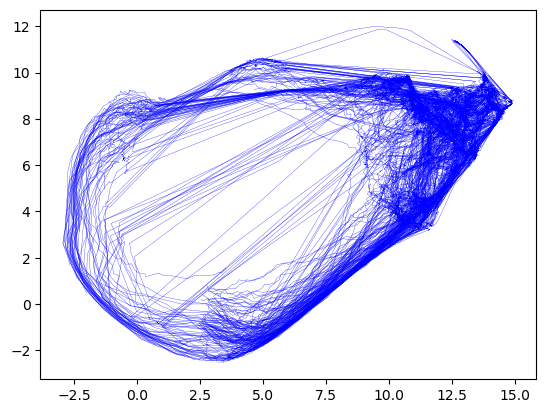

In [91]:
for val in range(1401,1600):
    tmp_id = cell_ind.index[cell_ind['id'] == val].tolist()
    plt.plot(embedding_all_prot[tmp_id,0], embedding_all_prot[tmp_id,1], c='blue', lw=0.2)

In [84]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.collections as mcoll
import matplotlib.path as mpath

def colorline(
    x, y, z=None, cmap=plt.get_cmap('copper'), norm=plt.Normalize(0.0, 1.0),
        linewidth=3, alpha=1.0):
    """
    http://nbviewer.ipython.org/github/dpsanders/matplotlib-examples/blob/master/colorline.ipynb
    http://matplotlib.org/examples/pylab_examples/multicolored_line.html
    Plot a colored line with coordinates x and y
    Optionally specify colors in the array z
    Optionally specify a colormap, a norm function and a line width
    """

    # Default colors equally spaced on [0,1]:
    if z is None:
        z = np.linspace(0.0, 1.0, len(x))

    # Special case if a single number:
    if not hasattr(z, "__iter__"):  # to check for numerical input -- this is a hack
        z = np.array([z])

    z = np.asarray(z)

    segments = make_segments(x, y)
    lc = mcoll.LineCollection(segments, array=z, cmap=cmap, norm=norm,
                              linewidth=linewidth, alpha=alpha)

    ax = plt.gca()
    ax.add_collection(lc)

    return lc


def make_segments(x, y):
    """
    Create list of line segments from x and y coordinates, in the correct format
    for LineCollection: an array of the form numlines x (points per line) x 2 (x
    and y) array
    """

    points = np.array([x, y]).T.reshape(-1, 1, 2)
    segments = np.concatenate([points[:-1], points[1:]], axis=1)
    return segments



In [53]:
val = 1205

In [82]:
def find_dist(x,y):
    dist_met = []
    for num in range(len(x)-1):
        p1 = np.array((x[num], y[num]))
        p2 = np.array((x[num+1], y[num+1]))
        tmp_dist = np.linalg.norm(p1 - p2)
        dist_met.append(tmp_dist)
        
        
    return dist_met
        
        

In [ ]:
dist_met = find_dist(embedding_all_prot[tmp_id,0], embedding_all_prot[tmp_id,1])

In [ ]:
dist_met

In [ ]:
tmp_id = cell_ind.index[cell_ind['id'] == 1300].tolist()
plt.plot(embedding_all_prot[tmp_id,0], embedding_all_prot[tmp_id,1], c='blue', lw=0.2)
len(embedding_all_prot[tmp_id,0])

In [ ]:
segments = make_segments(x, y)

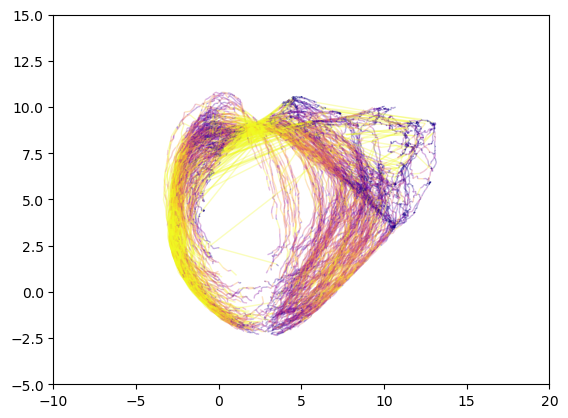

In [86]:
for val in range(1201,1400):
    tmp_id = cell_ind.index[cell_ind['id'] == val].tolist()
    dist_met = find_dist(embedding_all_prot[tmp_id,0], embedding_all_prot[tmp_id,1])
    colorline(embedding_all_prot[tmp_id,0], embedding_all_prot[tmp_id,1], dist_met, cmap=plt.get_cmap('plasma'), 
              norm=plt.Normalize(0.1, 0.4), linewidth=1, alpha=0.3)
    plt.xlim(-10,20)
    plt.ylim(-5,15)
    #plt.title('Int +ERL Divs')
    

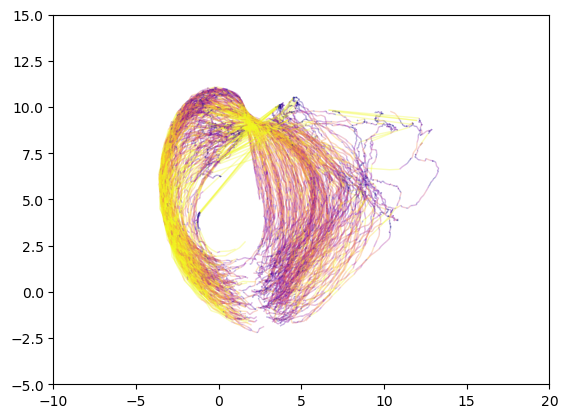

In [93]:
for val in range(801,1000):
    tmp_id = cell_ind.index[cell_ind['id'] == val].tolist()
    dist_met = find_dist(embedding_all_prot[tmp_id,0], embedding_all_prot[tmp_id,1])
    colorline(embedding_all_prot[tmp_id,0], embedding_all_prot[tmp_id,1], dist_met, cmap=plt.get_cmap('plasma'), 
              norm=plt.Normalize(0.1, 0.4), linewidth=1, alpha=0.3)
    plt.xlim(-10,20)
    plt.ylim(-5,15)
    

In [ ]:
test = np.log(dist_met)
z = dist_met
colorline(x, y, z, cmap=plt.get_cmap('plasma'), norm=plt.Normalize(0, 0.5), linewidth=2)
plt.xlim(-10,20)
plt.ylim(-5,15)



In [ ]:
max(test)

In [ ]:
N = 10
np.random.seed(101)
x = np.random.rand(N)
y = np.random.rand(N)
fig, ax = plt.subplots()

path = mpath.Path(np.column_stack([x, y]))
verts = path.interpolated(steps=3).vertices
x, y = verts[:, 0], verts[:, 1]
z = np.linspace(0, 1, len(x))
colorline(x, y, z, cmap=plt.get_cmap('jet'), linewidth=2)

plt.show()